<a href="https://colab.research.google.com/github/Jucksun/gsp-csice-research/blob/main/practiqueOriginal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install pygsp

S: (8, 8)
U: (8, 8)
gamma true: [ 1.2 -0.8  1.5 -1.1  0.7  1.3 -0.9  1. ]
first Omega: [3 6]
first y: [-0.505 -0.99 ]
covariance error: 0.30217663819890944


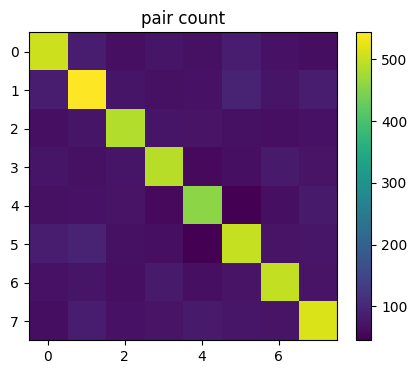

true: [ 1.2 -0.8  1.5 -1.1  0.7  1.3 -0.9  1. ]
est : [ 1.448 -0.733  1.506 -1.151  0.567  1.189 -0.965  0.873]
gamma error: 0.11169403159170523


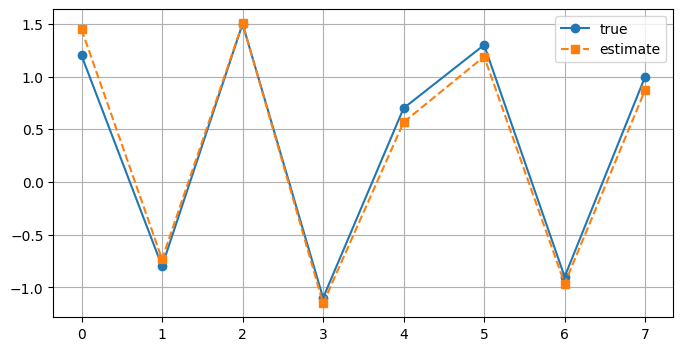

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(10)

# parameters
N = 8
M = 2000
m = 2
rho = 0.35


# graph
def path_laplacian(N):
    A = np.zeros((N,N))

    for j in range(N-1):
        A[j,j+1 % N] = 1
        A[j+1 % N,j] = 1

    D = np.diag(A.sum(axis=1))
    return D-A


S = path_laplacian(N)
lam, U = np.linalg.eigh(S)

print("S:", S.shape)
print("U:", U.shape)


# source covariance and true channel
C_hat_x = (1-rho)*np.eye(N) + rho*np.ones((N,N))

gamma_true = np.array([1.2,-0.8,1.5,-1.1,0.7,1.3,-0.9,1.0])
H = U @ np.diag(gamma_true) @ U.T


# synthetic signals
X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M)
X = X_hat @ U.T
Z = X @ H.T

print("gamma true:", gamma_true)


# partial observations
Omegas = []
ys = []

for i in range(M):
    Omega = np.sort(rng.choice(N, size=m, replace=False))
    y = Z[i,Omega]

    Omegas.append(Omega)
    ys.append(y)

print("first Omega:", Omegas[0])
print("first y:", np.round(ys[0],3))


# estimate covariance from observed pairs
total = np.zeros((N,N))
count = np.zeros((N,N))

for Omega, y in zip(Omegas, ys):
    total[np.ix_(Omega,Omega)] += np.outer(y,y)
    count[np.ix_(Omega,Omega)] += 1

C_z_est = np.zeros((N,N))

ind = count > 0
C_z_est[ind] = total[ind] / count[ind]


# only for checking in this synthetic example
C_z_true = Z.T @ Z / M

err_cov = np.linalg.norm(C_z_est-C_z_true,'fro') / np.linalg.norm(C_z_true,'fro')

print("covariance error:", err_cov)

plt.figure(figsize=(5,4))
plt.imshow(count)
plt.colorbar()
plt.title("pair count")
plt.show()


# graph Fourier covariance
C_hat_z_est = U.T @ C_z_est @ U


# recover magnitude
gamma_abs = np.sqrt(
    np.maximum(np.diag(C_hat_z_est)/np.diag(C_hat_x),0)
)


# recover relative signs
gamma_sign = np.ones(N)

for q in range(1,N):
    r = C_hat_z_est[0,q] / C_hat_x[0,q]
    gamma_sign[q] = 1 if r >= 0 else -1

gamma_est = gamma_abs * gamma_sign


# only for checking the global sign
if np.dot(gamma_est,gamma_true) < 0:
    gamma_est = -gamma_est

err_gamma = np.linalg.norm(gamma_est-gamma_true) / np.linalg.norm(gamma_true)

print("true:", np.round(gamma_true,3))
print("est :", np.round(gamma_est,3))
print("gamma error:", err_gamma)

plt.figure(figsize=(8,4))
plt.plot(gamma_true,'o-',label='true')
plt.plot(gamma_est,'s--',label='estimate')
plt.grid(True)
plt.legend()
plt.show()


In [ ]:
import pygsp as pg
import numpy as np
import scipy as sp
import pandas as pd

sn1 = np.array([
    [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], # 0: Self
    [1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], # 1: Handler
    [0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0], # 2-4: Test Subjects (Group A)
    [0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0], # 5: Challenge
    [0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0], # 6: Guard
    [0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0], # 7-13: Test Subjects (Group B)
    [0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1],
    [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0]])  # 14: Key

profiles = np.array([
    #  H     E     X     A     C     O    GMF   LMF   CCoeff
    [0.20, 0.90, 0.10, 0.30, 0.20, 0.95, 0.10, 0.05, 1.81],  # 0: Self
    [0.85, 0.30, 0.50, 0.60, 0.90, 0.40, 0.85, 0.80, 1.35],  # 1: Handler (Rigid, High C, Low GMF)
    [0.50, 0.70, 0.40, 0.50, 0.40, 0.60, 0.30, 0.25, 1.52],  # 2: Test Subj 1
    [0.40, 0.85, 0.30, 0.40, 0.30, 0.75, 0.20, 0.15, 1.68],  # 3: Test Subj 2 (High Anomalous Match)
    [0.60, 0.60, 0.40, 0.60, 0.50, 0.50, 0.35, 0.30, 1.49],  # 4: Test Subj 3
    [0.90, 0.20, 0.60, 0.40, 0.95, 0.30, 0.90, 0.95, 1.38],  # 5: Challenge (High Discipline/Complexity Firewall)
    [0.70, 0.25, 0.30, 0.50, 0.80, 0.30, 0.70, 0.75, 1.32],  # 6: Guard
    [0.30, 0.80, 0.70, 0.70, 0.30, 0.80, 0.15, 0.20, 1.62],  # 7: Test Subj 4 (High Social, High Anomalous)
    [0.40, 0.75, 0.65, 0.60, 0.40, 0.70, 0.25, 0.20, 1.58],  # 8: Test Subj 5
    [0.50, 0.65, 0.80, 0.75, 0.35, 0.65, 0.30, 0.35, 1.50],  # 9: Test Subj 6
    [0.60, 0.50, 0.60, 0.60, 0.50, 0.50, 0.40, 0.45, 1.45],  # 10: Test Subj 7
    [0.35, 0.80, 0.75, 0.70, 0.25, 0.85, 0.15, 0.10, 1.72],  # 11: Test Subj 8 (High Anomalous Conductor)
    [0.25, 0.85, 0.85, 0.80, 0.20, 0.90, 0.10, 0.10, 1.78],  # 12: Test Subj 9 (Near-Perfect Anomalous Mirror)
    [0.40, 0.70, 0.70, 0.65, 0.30, 0.75, 0.20, 0.15, 1.65],  # 13: Test Subj 10
    [0.80, 0.20, 0.20, 0.30, 0.90, 0.40, 0.95, 0.90, 1.47]   # 14: Key
])

similarity = profiles @ profiles.T

W = sn1 * similarity

dwell_weights = np.sum(profiles, axis=1) * 0.5
np.fill_diagonal(W, dwell_weights)

D = np.diag(np.sum(sn1, axis=0))

L = D - sn1

P = W / W.sum(axis=1, keepdims=True)

df = pd.DataFrame(P[5], columns=["Probability of Jumping From Node 5 To:"])
print(df.T.to_string())

print(L)

print("\n", D)

print("\n", similarity)

print("\n", W)

                                         0    1         2        3         4         5         6         7         8        9         10   11   12   13   14
Probability of Jumping From Node 5 To:  0.0  0.0  0.108244  0.10375  0.114078  0.084891  0.130925  0.108773  0.111607  0.11766  0.120072  0.0  0.0  0.0  0.0
[[ 1 -1  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [-1  4 -1 -1 -1  0  0  0  0  0  0  0  0  0  0]
 [ 0 -1  3 -1  0 -1  0  0  0  0  0  0  0  0  0]
 [ 0 -1 -1  4 -1 -1  0  0  0  0  0  0  0  0  0]
 [ 0 -1  0 -1  3 -1  0  0  0  0  0  0  0  0  0]
 [ 0  0 -1 -1 -1  8 -1 -1 -1 -1 -1  0  0  0  0]
 [ 0  0  0  0  0 -1  4 -1  0  0  0 -1 -1  0  0]
 [ 0  0  0  0  0 -1 -1  5 -1  0  0 -1 -1  0  0]
 [ 0  0  0  0  0 -1  0 -1  6 -1  0 -1 -1 -1  0]
 [ 0  0  0  0  0 -1  0  0 -1  5 -1  0 -1 -1  0]
 [ 0  0  0  0  0 -1  0  0  0 -1  4  0 -1 -1  0]
 [ 0  0  0  0  0  0 -1 -1 -1  0  0  5 -1  0 -1]
 [ 0  0  0  0  0  0 -1 -1 -1 -1 -1 -1  8 -1 -1]
 [ 0  0  0  0  0  0  0  0 -1 -1 -1  0 -1  5 -1]
 [ 0  0  0  0 

In [ ]:
profiles = np.array([
    #  H     E     X     A     C     O    GMF   LMF   CCoeff
    [0.20, 0.90, 0.10, 0.30, 0.20, 0.95, 0.10, 0.05, 1.81],  # 0: Self
    [0.85, 0.30, 0.50, 0.60, 0.90, 0.40, 0.85, 0.80, 1.35],  # 1: Handler (Rigid, High C, Low GMF)
    [0.50, 0.70, 0.40, 0.50, 0.40, 0.60, 0.30, 0.25, 1.52],  # 2: Test Subj 1
    [0.40, 0.85, 0.30, 0.40, 0.30, 0.75, 0.20, 0.15, 1.68],  # 3: Test Subj 2 (High Anomalous Match)
    [0.60, 0.60, 0.40, 0.60, 0.50, 0.50, 0.35, 0.30, 1.49],  # 4: Test Subj 3
    [0.90, 0.20, 0.60, 0.40, 0.95, 0.30, 0.90, 0.95, 1.38],  # 5: Challenge (High Discipline/Complexity Firewall)
    [0.70, 0.25, 0.30, 0.50, 0.80, 0.30, 0.70, 0.75, 1.32],  # 6: Guard
    [0.30, 0.80, 0.70, 0.70, 0.30, 0.80, 0.15, 0.20, 1.62],  # 7: Test Subj 4 (High Social, High Anomalous)
    [0.40, 0.75, 0.65, 0.60, 0.40, 0.70, 0.25, 0.20, 1.58],  # 8: Test Subj 5
    [0.50, 0.65, 0.80, 0.75, 0.35, 0.65, 0.30, 0.35, 1.50],  # 9: Test Subj 6
    [0.60, 0.50, 0.60, 0.60, 0.50, 0.50, 0.40, 0.45, 1.45],  # 10: Test Subj 7
    [0.35, 0.80, 0.75, 0.70, 0.25, 0.85, 0.15, 0.10, 1.72],  # 11: Test Subj 8 (High Anomalous Conductor)
    [0.25, 0.85, 0.85, 0.80, 0.20, 0.90, 0.10, 0.10, 1.78],  # 12: Test Subj 9 (Near-Perfect Anomalous Mirror)
    [0.40, 0.70, 0.70, 0.65, 0.30, 0.75, 0.20, 0.15, 1.65],  # 13: Test Subj 10
    [0.80, 0.20, 0.20, 0.30, 0.90, 0.40, 0.95, 0.90, 1.47]   # 14: Key
])
N = 15
W = np.zeros((N, N))

for i in range(N):
    for j in range(N):
        if sn1[i, j] == 1:
            # HEXACO Similarity
            hexaco_sim = np.dot(profiles[i, :6], profiles[j, :6])

            # Mimicry Ease (Lower simplicity = easier)
            mimicry_ease = (1.0 - profiles[j, 6]) * (1.0 - profiles[j, 7])

            # Consciousness Resonance with Silent Night (Node 0)
            c_diff = abs(profiles[j, 8] - profiles[0, 8])
            c_resonance = np.exp(-2.0 * c_diff)

            W[i, j] = hexaco_sim * mimicry_ease * c_resonance

# Dwell friction on diagonal
for i in range(N):
    conscientiousness = profiles[i, 4]
    complexity = profiles[i, 6] + profiles[i, 7]
    W[i, i] = (conscientiousness + complexity) * 1.2

# Normalize rows to create probability matrix P
P = W / W.sum(axis=1, keepdims=True)

# ---------------------------------------------------------
# 4. RUN MONTE CARLO SIMULATION
# ---------------------------------------------------------
def run_single_simulation(start_node=0, target_node=14, max_steps=1000):
    current_node = start_node
    path = [current_node]
    node_dwell_times = {i: 0 for i in range(15)}

    for step in range(max_steps):
        node_dwell_times[current_node] += 1

        if current_node == target_node:
            return path, node_dwell_times, True # Key reached!

        next_node = np.random.choice(15, p=P[current_node])
        current_node = next_node
        path.append(current_node)

    return path, node_dwell_times, False

N_TRIALS = 1000
total_steps = []
all_dwells = {i: [] for i in range(15)}
successful_paths = 0

for _ in range(N_TRIALS):
    path, dwell, success = run_single_simulation()
    if success:
        successful_paths += 1
        total_steps.append(len(path))
        for node, count in dwell.items():
            all_dwells[node].append(count)

# ---------------------------------------------------------
# 5. PRINT ALL RESULTS (NODES 0 TO 14)
# ---------------------------------------------------------
node_roles = [
    "Node 0: Self (Silent Night)", "Node 1: Handler", "Node 2: Test Subj 1 (Group A)",
    "Node 3: Test Subj 2 (Group A)", "Node 4: Test Subj 3 (Group A)", "Node 5: Challenge Node (Firewall)",
    "Node 6: Guard", "Node 7: Test Subj 4 (Group B)", "Node 8: Test Subj 5 (Group B)",
    "Node 9: Test Subj 6 (Group B)", "Node 10: Test Subj 7 (Group B)", "Node 11: Test Subj 8 (Group B)",
    "Node 12: Test Subj 9 (Group B)", "Node 13: Test Subj 10 (Group B)", "Node 14: Key"
]

results_data = []
for i in range(15):
    results_data.append({
        "Node ID": i,
        "Role / Person": node_roles[i],
        "C_Coeff": profiles[i, 8],
        "Avg Dwell Time (Ticks)": np.round(np.mean(all_dwells[i]), 2)
    })

df_results = pd.DataFrame(results_data)

# Force pandas to print ALL rows without truncating
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("=" * 70)
print(f"HEXACO + ANOMALOUS MONTE CARLO SIMULATION RESULTS ({N_TRIALS} TRIALS)")
print(f"Success Rate: {(successful_paths / N_TRIALS) * 100:.1f}%")
print(f"Average Path Length to Key: {np.mean(total_steps):.2f} steps")
print("=" * 70)
print(df_results.to_string(index=False))
print("=" * 70)

HEXACO + ANOMALOUS MONTE CARLO SIMULATION RESULTS (1000 TRIALS)
Success Rate: 8.5%
Average Path Length to Key: 657.56 steps
 Node ID                     Role / Person  C_Coeff  Avg Dwell Time (Ticks)
       0       Node 0: Self (Silent Night)     1.81                   73.95
       1                   Node 1: Handler     1.35                   10.46
       2     Node 2: Test Subj 1 (Group A)     1.52                   68.01
       3     Node 3: Test Subj 2 (Group A)     1.68                  101.02
       4     Node 4: Test Subj 3 (Group A)     1.49                   62.32
       5 Node 5: Challenge Node (Firewall)     1.38                    2.49
       6                     Node 6: Guard     1.32                    2.54
       7     Node 7: Test Subj 4 (Group B)     1.62                   45.98
       8     Node 8: Test Subj 5 (Group B)     1.58                   51.47
       9     Node 9: Test Subj 6 (Group B)     1.50                   25.16
      10    Node 10: Test Subj 7 (Group 

In [ ]:
def run_single_simulation(start_node=0, target_node=14, max_steps=500):
    current_node = start_node
    path = [current_node]
    node_dwell_times = {i: 0 for i in range(15)}

    for step in range(max_steps):
        node_dwell_times[current_node] += 1

        if current_node == target_node:
            return path, node_dwell_times, True # Target reached!

        # Sample next node based on transition probabilities
        next_node = np.random.choice(15, p=P[current_node])
        current_node = next_node
        path.append(current_node)

    return path, node_dwell_times, False # Timed out

# Run 1,000 Monte Carlo Trials
N_TRIALS = 1000
total_steps = []
all_dwells = {i: [] for i in range(15)}
successful_paths = 0

for _ in range(N_TRIALS):
    path, dwell, success = run_single_simulation()
    if success:
        successful_paths += 1
        total_steps.append(len(path))
        for node, count in dwell.items():
            all_dwells[node].append(count)

# ---------------------------------------------------------
# 5. DISPLAY RESULTS & METRICS
# ---------------------------------------------------------
print("=== SIMULATION RESULTS ===")
print(f"Total Traversal Attempts: {N_TRIALS}")
print(f"Success Rate: {(successful_paths / N_TRIALS) * 100:.1f}%")
print(f"Average Steps to Retrieve Key (Node 14): {np.mean(total_steps):.2f} time units")

# Average Dwell Time Table
dwell_summary = []
node_roles = [
    "0: Self", "1: Handler", "2: Test Subj 1", "3: Test Subj 2", "4: Test Subj 3",
    "5: Challenge", "6: Guard", "7: Test Subj 4", "8: Test Subj 5", "9: Test Subj 6",
    "10: Test Subj 7", "11: Test Subj 8", "12: Test Subj 9", "13: Test Subj 10", "14: Key"
]

for i in range(15):
    dwell_summary.append({
        "Node / Person": node_roles[i],
        "Avg Dwell Time (Ticks)": np.round(np.mean(all_dwells[i]), 2)
    })

print("\n=== AVERAGE TIME SPENT IN EACH PERSON'S MIND ===")
df_dwell = pd.DataFrame(dwell_summary)
print(df_dwell.to_string(index=False))

=== SIMULATION RESULTS ===
Total Traversal Attempts: 1000
Success Rate: 2.5%
Average Steps to Retrieve Key (Node 14): 362.64 time units

=== AVERAGE TIME SPENT IN EACH PERSON'S MIND ===
   Node / Person  Avg Dwell Time (Ticks)
         0: Self                   54.44
      1: Handler                    9.16
  2: Test Subj 1                   47.84
  3: Test Subj 2                   67.76
  4: Test Subj 3                   39.48
    5: Challenge                    2.04
        6: Guard                    1.28
  7: Test Subj 4                   20.36
  8: Test Subj 5                   21.24
  9: Test Subj 6                   10.48
 10: Test Subj 7                    5.92
 11: Test Subj 8                   23.00
 12: Test Subj 9                   40.48
13: Test Subj 10                   18.16
         14: Key                    1.00


S: (15, 15)
U: (15, 15)
gamma true: [ 1.2 -0.8  1.5 -1.1  0.7  1.3 -0.9  1.   0.5 -1.4  0.9 -0.6  1.1 -0.7
  1. ]
first Omega: [ 6 14]
first y: [-1.321  0.269]
covariance error: 0.5679453941845116


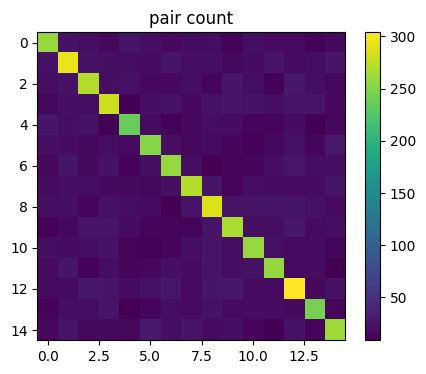

true: [ 1.2 -0.8  1.5 -1.1  0.7  1.3 -0.9  1.   0.5 -1.4  0.9 -0.6  1.1 -0.7
  1. ]
est : [ 1.027 -0.843  1.66  -1.092  0.743  1.158 -0.754  1.092  0.42  -1.655
  1.024 -0.254  1.09  -0.558  1.069]
gamma error: 0.1478041220902977


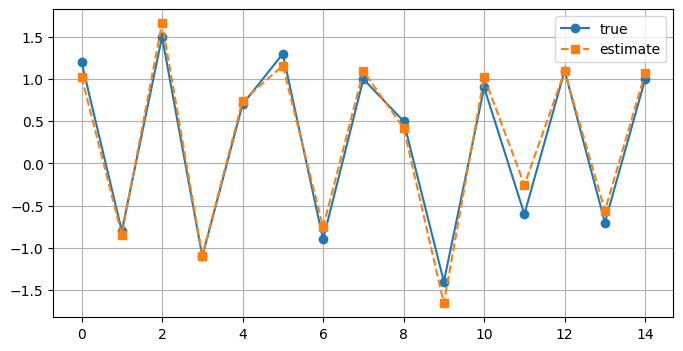

[[ 0.12725991  0.78241625  0.54493402 ...  0.79076799  0.77349474
   1.41122839]
 [ 0.94961867  0.72589626  1.7714498  ...  1.88293031  0.11385653
   1.18699326]
 [-1.28770005  0.10696277  0.33958571 ...  0.79937679  0.17155038
   1.0908532 ]
 ...
 [ 0.4329759  -0.04650611 -0.94254925 ...  0.13768007 -0.4716136
  -1.55048247]
 [-0.58533692  1.06318107  0.50348513 ...  1.44487948 -0.22211923
   0.01477892]
 [ 0.30961399  0.43998044 -0.66892468 ...  0.73341435  1.1393337
   0.15500345]]
(15, 15)
[2 2 2]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(10)

# parameters
N = 15
M = 2000
m = 2
rho = 0.35


# graph
def path_laplacian(N):
    A = np.zeros((N,N))

    for j in range(N-1):
        A[j,j+1 % N] = 1
        A[j+1 % N,j] = 1

    D = np.diag(A.sum(axis=1))
    return D-A


S = sn1
lam, U = np.linalg.eigh(S)

print("S:", S.shape)
print("U:", U.shape)


# source covariance and true channel
C_hat_x = (1-rho)*np.eye(N) + rho*np.ones((N,N))

gamma_true = np.array([1.2, -0.8, 1.5, -1.1, 0.7, 1.3, -0.9, 1.0,0.5, -1.4, 0.9, -0.6, 1.1, -0.7, 1.0])
H = U @ np.diag(gamma_true) @ U.T


# synthetic signals
X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M)
X = X_hat @ U.T
Z = X @ H.T

print("gamma true:", gamma_true)


# partial observations
Omegas = []
ys = []

for i in range(M):
    Omega = np.sort(rng.choice(N, size=m, replace=False))
    y = Z[i,Omega]

    Omegas.append(Omega)
    ys.append(y)

print("first Omega:", Omegas[0])
print("first y:", np.round(ys[0],3))


# estimate covariance from observed pairs
total = np.zeros((N,N))
count = np.zeros((N,N))

for Omega, y in zip(Omegas, ys):
    total[np.ix_(Omega,Omega)] += np.outer(y,y)
    count[np.ix_(Omega,Omega)] += 1

C_z_est = np.zeros((N,N))

ind = count > 0
C_z_est[ind] = total[ind] / count[ind]


# only for checking in this synthetic example
C_z_true = Z.T @ Z / M

err_cov = np.linalg.norm(C_z_est-C_z_true,'fro') / np.linalg.norm(C_z_true,'fro')

print("covariance error:", err_cov)

plt.figure(figsize=(5,4))
plt.imshow(count)
plt.colorbar()
plt.title("pair count")
plt.show()


# graph Fourier covariance
C_hat_z_est = U.T @ C_z_est @ U


# recover magnitude
gamma_abs = np.sqrt(
    np.maximum(np.diag(C_hat_z_est)/np.diag(C_hat_x),0)
)


# recover relative signs
gamma_sign = np.ones(N)

for q in range(1,N):
    r = C_hat_z_est[0,q] / C_hat_x[0,q]
    gamma_sign[q] = 1 if r >= 0 else -1

gamma_est = gamma_abs * gamma_sign


# only for checking the global sign
if np.dot(gamma_est,gamma_true) < 0:
    gamma_est = -gamma_est

err_gamma = np.linalg.norm(gamma_est-gamma_true) / np.linalg.norm(gamma_true)

print("true:", np.round(gamma_true,3))
print("est :", np.round(gamma_est,3))
print("gamma error:", err_gamma)

plt.figure(figsize=(8,4))
plt.plot(gamma_true,'o-',label='true')
plt.plot(gamma_est,'s--',label='estimate')
plt.grid(True)
plt.legend()
plt.show()



print(X_hat)

print(C_z_est.shape)

dsds = np.array([[1, 1, 1],
                 [2, 2, 2],
                 [3, 3, 3]])
print(dsds[1])

In [ ]:
# out[i, j] = a[i] * b[j]




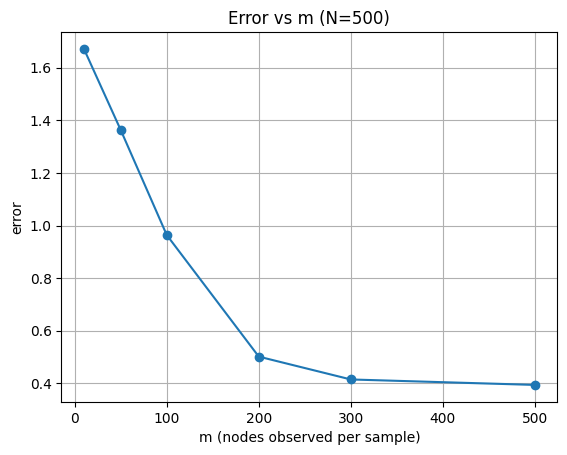

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def run(N, M, m, rho, seed=0):
    rng = np.random.default_rng(seed)

    # path graph
    A = np.zeros((N, N))
    for j in range(N - 1):
        A[j, j+1] = 1
        A[j+1, j] = 1
    S = np.diag(A.sum(axis=1)) - A
    lam, U = np.linalg.eigh(S)

    # random true gamma
    gamma_true = rng.uniform(0.5, 1.5, N) * rng.choice([-1, 1], N)
    H = U @ np.diag(gamma_true) @ U.T
    C_hat_x = (1 - rho) * np.eye(N) + rho * np.ones((N, N))

    # random signals
    X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M)
    Z = (X_hat @ U.T) @ H.T
    sigma = 1.0
    Z = Z + sigma * rng.standard_normal(Z.shape)

    # only see m nodes per sample
    total = np.zeros((N, N)); count = np.zeros((N, N))
    for i in range(M):
        Om = rng.choice(N, size=m, replace=False)
        y = Z[i, Om]
        total[np.ix_(Om, Om)] += np.outer(y, y)
        count[np.ix_(Om, Om)] += 1
    C_z_est = np.zeros((N, N))
    ind = count > 0
    C_z_est[ind] = total[ind] / count[ind]

    # recover gamma
    C_hat_z_est = U.T @ C_z_est @ U
    gamma_abs = np.sqrt(np.maximum(np.diag(C_hat_z_est) / np.diag(C_hat_x), 0))
    gamma_sign = np.ones(N)
    for q in range(1, N):
        gamma_sign[q] = 1 if C_hat_z_est[0, q] / C_hat_x[0, q] >= 0 else -1
    gamma_est = gamma_abs * gamma_sign
    if np.dot(gamma_est, gamma_true) < 0:
        gamma_est = -gamma_est

    return np.linalg.norm(gamma_est - gamma_true) / np.linalg.norm(gamma_true)

m_values = [10, 50, 100, 200, 300, 500]
errors = [run(N=500, M=1000, m=m, rho=0.35) for m in m_values]

plt.plot(m_values, errors, 'o-')
plt.xlabel("m (nodes observed per sample)")
plt.ylabel("error")
plt.title("Error vs m (N=500)")
plt.grid(True)
plt.show()

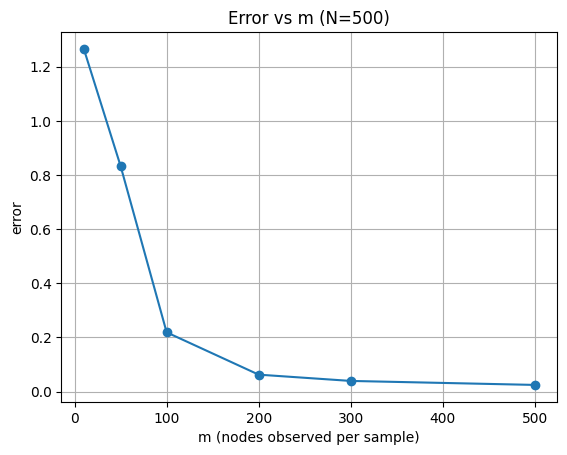

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def run(N, M, m, rho, seed=0):
    rng = np.random.default_rng(seed)

    # path graph
    A = np.zeros((N, N))
    for j in range(N - 1):
        A[j, j+1] = 1
        A[j+1, j] = 1
    S = np.diag(A.sum(axis=1)) - A
    lam, U = np.linalg.eigh(S)

    # random true gamma
    gamma_true = rng.uniform(0.5, 1.5, N) * rng.choice([-1, 1], N)
    H = U @ np.diag(gamma_true) @ U.T
    C_hat_x = (1 - rho) * np.eye(N) + rho * np.ones((N, N))

    # random signals
    X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M)
    Z = (X_hat @ U.T) @ H.T
    sigma = 0.0
    Z = Z + sigma * rng.standard_normal(Z.shape)

    # only see m nodes per sample
    total = np.zeros((N, N)); count = np.zeros((N, N))
    for i in range(M):
        Om = rng.choice(N, size=m, replace=False)
        y = Z[i, Om]
        total[np.ix_(Om, Om)] += np.outer(y, y)
        count[np.ix_(Om, Om)] += 1
    C_z_est = np.zeros((N, N))
    ind = count > 0
    C_z_est[ind] = total[ind] / count[ind]

    # recover gamma
    C_hat_z_est = U.T @ C_z_est @ U
    gamma_abs = np.sqrt(np.maximum(np.diag(C_hat_z_est) / np.diag(C_hat_x), 0))
    gamma_sign = np.ones(N)
    for q in range(1, N):
        gamma_sign[q] = 1 if C_hat_z_est[0, q] / C_hat_x[0, q] >= 0 else -1
    gamma_est = gamma_abs * gamma_sign
    if np.dot(gamma_est, gamma_true) < 0:
        gamma_est = -gamma_est

    return np.linalg.norm(gamma_est - gamma_true) / np.linalg.norm(gamma_true)

m_values = [10, 50, 100, 200, 300, 500]
errors = [run(N=500, M=1000, m=m, rho=0.35) for m in m_values]

plt.plot(m_values, errors, 'o-')
plt.xlabel("m (nodes observed per sample)")
plt.ylabel("error")
plt.title("Error vs m (N=500)")
plt.grid(True)
plt.show()